# Chapitre 13 - Lab : dégrouper la base avec PostgreSQL et Redis

Les cours de ce chapitre défendent une idée : une organisation peut se construire comme
une **base de données dégroupée** (« unbundled »), où un système de référence publie le
journal ordonné de ses changements et où index, caches et compteurs sont des **vues
dérivées**, entretenues par des consommateurs idempotents et recalculables à volonté. Ce
lab met l'idée à l'épreuve sur de vrais systèmes : **PostgreSQL 17** joue le système de
référence, son **décodage logique** (plugin `test_decoding`) fournit le flux de
changements, et **Redis 7** héberge un index inversé et des compteurs dérivés. On y
provoque des pannes de consommateur, un bogue dans la fonction de dérivation, des
relances de requêtes et des courses sur une contrainte d'unicité.

**Démarrer et arrêter les services** (depuis la racine du dépôt) :

```bash
docker compose -f docker/dataflow/compose.yml -p ddia_dataflow up -d
# ... exécuter le notebook ...
docker compose -f docker/dataflow/compose.yml -p ddia_dataflow down -v
```

PostgreSQL écoute sur le port **11332** de l'hôte (utilisateur, mot de passe et base :
`ddia`), lancé avec `wal_level=logical` ; Redis écoute sur le port **11379**.

**Plan.**

1. Le journal de changements du système de référence.
2. Entretenir des vues dérivées dans Redis, et mesurer leur retard.
3. Panne du consommateur : relivraison et idempotence.
4. `CREATE INDEX CONCURRENTLY` : une vue dérivée construite par instantané et rattrapage.
5. Faire confiance, mais vérifier : audit de bout en bout d'une vue dérivée.
6. Corriger par retraitement : dériver une nouvelle vue à côté de l'ancienne.
7. Identifiants de requête de bout en bout.
8. Contraintes d'unicité sous concurrence.

In [1]:
import random
import threading
import time
import uuid
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg
import redis
from psycopg import errors

from ddia.dataflow_pg import InvertedIndexView, parse_change, rebuild_index, tokenize
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.max_colwidth", 90)
DSN = "host=localhost port=11332 user=ddia password=ddia dbname=ddia connect_timeout=5"
R = redis.Redis(host="localhost", port=11379, decode_responses=True)

with psycopg.connect(DSN, autocommit=True) as c:
    print(c.execute("SELECT version()").fetchone()[0].split(",")[0])
    print("wal_level =", c.execute("SHOW wal_level").fetchone()[0])
print("Redis", R.info("server")["redis_version"], "ping :", R.ping())


def sql(q, params=None):
    """Exécute une requête dans une connexion autocommit et renvoie les lignes."""
    with psycopg.connect(DSN, autocommit=True) as c:
        cur = c.execute(q, params)
        return cur.fetchall() if cur.description else None


# remise à zéro : le notebook peut être rejoué
for (slot,) in sql("SELECT slot_name FROM pg_replication_slots"):
    sql("SELECT pg_drop_replication_slot(%s)", (slot,))
sql("DROP TABLE IF EXISTS doc, mesures, comptes, requetes, journal_effets, "
    "utilisateurs, utilisateurs_u, demandes_noms CASCADE")
R.flushdb()

PostgreSQL 17.11 on x86_64-pc-linux-musl
wal_level = logical
Redis 7.4.11 ping : True


True

## 1. Le journal de changements du système de référence (section *Reasoning about dataflows*)

Le premier conseil du chapitre est de savoir **où une donnée est écrite d'abord** et
quelles représentations en dérivent. Ici, l'application n'écrit que dans PostgreSQL
(table `doc` : des articles avec titre, corps et auteur). Tout le reste, l'index de
recherche et les compteurs par auteur dans Redis, est **dérivé** du flux de changements
de cette table, dans l'ordre où PostgreSQL les a validés. L'application n'écrit jamais
directement dans Redis : il n'y a donc pas de double écriture et pas de course entre
deux systèmes qui décideraient chacun d'un ordre (chapitre 12).

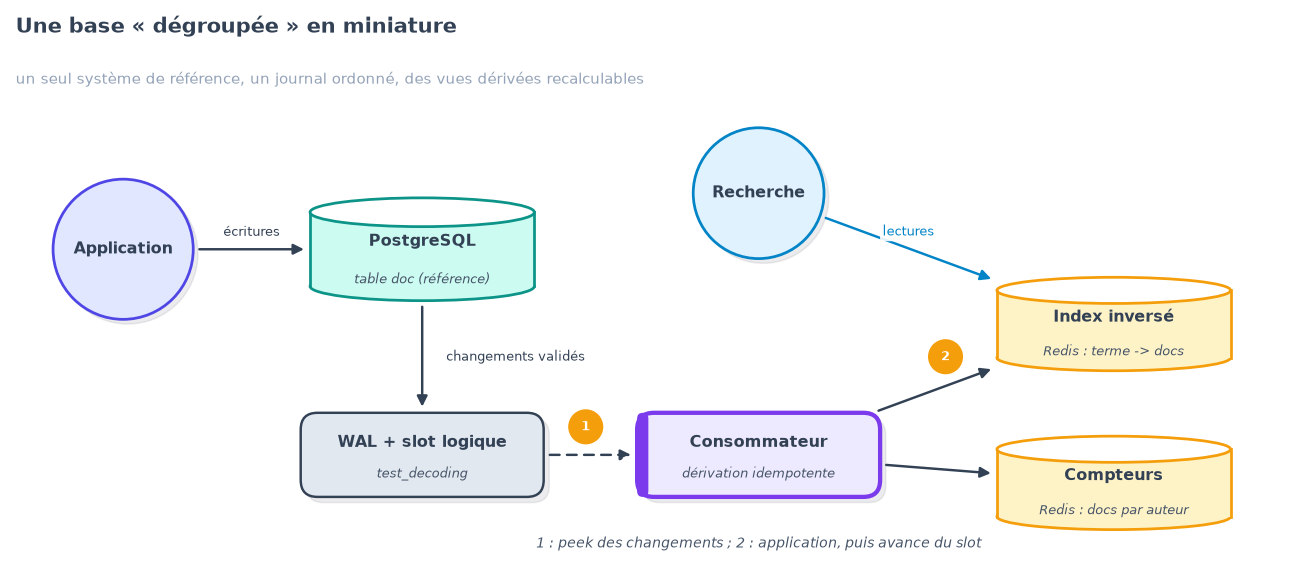

In [2]:
d = Diagram(13.6, 5.0, title="Une base « dégroupée » en miniature",
            subtitle="un seul système de référence, un journal ordonné, des vues dérivées recalculables")
d.box("app", 1.2, 3.4, "Application", kind="user", w=1.5, color=INDIGO)
d.box("pg", 4.4, 3.4, "PostgreSQL", sub="table doc (référence)", kind="db", color=TEAL, w=2.4, h=1.1)
d.box("wal", 4.4, 1.2, "WAL + slot logique", sub="test_decoding", color=SLATE, w=2.6)
d.box("cons", 8.0, 1.2, "Consommateur", sub="dérivation idempotente", color=VIOLET, w=2.6, kind="model")
d.box("idx", 11.8, 2.6, "Index inversé", sub="Redis : terme -> docs", kind="db", color=AMBER, w=2.5, h=1.0)
d.box("cnt", 11.8, 0.9, "Compteurs", sub="Redis : docs par auteur", kind="db", color=AMBER, w=2.5, h=1.0)
d.box("q", 8.0, 4.0, "Recherche", kind="user", w=1.4, color=SKY)
d.arrow("app", "pg", "écritures")
d.arrow("pg", "wal", "changements validés", label_offset=(1.0, 0))
d.arrow("wal", "cons", style="dashed")
d.arrow("cons", "idx")
d.arrow("cons", "cnt")
d.arrow("q", "idx", "lectures", color=SKY)
d.badge(6.15, 1.5, "1"); d.badge(10.0, 2.25, "2")
d.note(8.0, 0.25, "1 : peek des changements ; 2 : application, puis avance du slot")
d.show()

Un **slot de réplication logique** est un curseur durable sur le journal d'écriture
(WAL) : PostgreSQL conserve tout le journal qui n'a pas encore été confirmé par ce
consommateur. `pg_logical_slot_peek_changes` lit les changements sans faire avancer le
curseur ; `pg_replication_slot_advance` le fait avancer une fois les changements
appliqués. C'est exactement l'offset d'un consommateur de journal du chapitre
12, géré par la base elle-même.

In [3]:
sql("""CREATE TABLE doc (id integer PRIMARY KEY, titre text NOT NULL, corps text NOT NULL,
                         auteur text)""")
sql("SELECT pg_create_logical_replication_slot('vues', 'test_decoding')")


def peek(slot, max_rows=None):
    return sql("SELECT lsn::text, xid::text, data FROM pg_logical_slot_peek_changes(%s, NULL, %s)",
               (slot, max_rows))


def advance(slot, lsn):
    sql("SELECT pg_replication_slot_advance(%s, %s::pg_lsn)", (slot, lsn))


sql("INSERT INTO doc VALUES (1, 'Journaux et flux', 'Le journal ordonne les événements', 'ana')")
sql("UPDATE doc SET titre = 'Journaux, flux et vues' WHERE id = 1")
with psycopg.connect(DSN) as c:      # une transaction de deux changements
    c.execute("INSERT INTO doc VALUES (2, 'L''index dérivé', 'Une vue sur les données', 'bob')")
    c.execute("DELETE FROM doc WHERE id = 1")
brut = pd.DataFrame(peek("vues"), columns=["lsn", "xid", "data"])
brut

,lsn,xid,data
0,0/26EF8E60,19473,BEGIN 19473
1,0/26EF8E60,19473,table public.doc: INSERT: id[integer]:1 titre[text]:'Journaux et flux' corps[text]:'Le...
2,0/26EF8FA8,19473,COMMIT 19473
3,0/26EF8FA8,19474,BEGIN 19474
4,0/26EF8FA8,19474,"table public.doc: UPDATE: id[integer]:1 titre[text]:'Journaux, flux et vues' corps[tex..."
5,0/26EF9060,19474,COMMIT 19474
6,0/26EF9060,19475,BEGIN 19475
7,0/26EF9060,19475,table public.doc: INSERT: id[integer]:2 titre[text]:'L''index dérivé' corps[text]:'Une...
8,0/26EF9110,19475,table public.doc: DELETE: id[integer]:1
9,0/26EF9180,19475,COMMIT 19475


Chaque transaction validée apparaît entre un `BEGIN` et un `COMMIT`, dans l'ordre de
validation, avec l'image complète de la nouvelle ligne pour `INSERT` et `UPDATE` (et la
clé seule pour `DELETE`, l'identité de réplique par défaut). Le parseur
`parse_change` du module `ddia/dataflow_pg.py` transforme ces lignes en changements
structurés :

In [4]:
pd.DataFrame([dict(op=c["op"], **c["row"]) for c in map(parse_change, brut["data"]) if c])

,op,id,titre,corps,auteur
0,INSERT,1,Journaux et flux,Le journal ordonne les événements,ana
1,UPDATE,1,"Journaux, flux et vues",Le journal ordonne les événements,ana
2,INSERT,2,L'index dérivé,Une vue sur les données,bob
3,DELETE,1,NaN,NaN,NaN


> **À retenir.** Le système de référence décide seul de l'ordre des écritures ; son
> journal de changements, lu à travers un slot logique (un offset durable), est l'unique
> entrée des systèmes dérivés.

## 2. Entretenir des vues dérivées dans Redis, et mesurer leur retard (section *The meta-database of everything*)

Le consommateur applique chaque changement à deux vues Redis : un **index inversé**
(`t:<terme>` = ensemble des documents contenant le terme) et un **compteur de documents
par auteur** (un hash). Pour rester **idempotent**, il mémorise pour chaque document ses
termes (`doc:<id>`) et son auteur (`auth:<id>`) : appliquer un changement consiste à
retirer l'ancienne contribution du document puis à ajouter la nouvelle, le tout dans une
transaction Redis (`MULTI`). Rejouer un changement déjà appliqué ne modifie donc rien.
Pour comparaison, il entretient aussi un compteur **naïf** du nombre total de documents
(`INCR` sur insertion, `DECR` sur suppression), qui n'est pas idempotent.

C'est ce que fait une base quand elle maintient un index secondaire, mais l'index est
ici un autre logiciel, sur une autre machine potentiellement, entretenu par du code
applicatif : la base de toute l'organisation devient une « méta-base ».

In [5]:
def apply_redis(ch, v="v1", tok=tokenize):
    """Applique un changement à la vue `v` (idempotent), plus le compteur naïf."""
    p = f"idx:{v}:"
    i = ch["row"]["id"]
    old_terms, old_auth = R.smembers(p + f"doc:{i}"), R.get(p + f"auth:{i}")
    pipe = R.pipeline(transaction=True)
    for t in old_terms:
        pipe.srem(p + "t:" + t, i)
    pipe.delete(p + f"doc:{i}", p + f"auth:{i}")
    if old_auth:
        pipe.hincrby(p + "auteurs", old_auth, -1)
    if ch["op"] != "DELETE":
        row = ch["row"]
        terms = tok(row["titre"]) | tok(row["corps"])
        for t in terms:
            pipe.sadd(p + "t:" + t, i)
        if terms:
            pipe.sadd(p + f"doc:{i}", *terms)
        if row["auteur"]:
            pipe.set(p + f"auth:{i}", row["auteur"])
            pipe.hincrby(p + "auteurs", row["auteur"], 1)
    pipe.incrby(p + "naif_total", {"INSERT": 1, "DELETE": -1}.get(ch["op"], 0))
    pipe.execute()


class Crash(Exception):
    """Panne simulée du consommateur."""


def consume(slot, v="v1", max_rows=None, crash_after=None, tok=tokenize):
    """Lit les changements du slot, les applique, puis avance le slot jusqu'au dernier COMMIT.
    crash_after=k : panne après k changements appliqués, avant l'avance du slot."""
    rows, applied, last_commit = peek(slot, max_rows), 0, None
    for lsn, _, data in rows:
        if data.startswith("COMMIT"):
            last_commit = lsn
            continue
        ch = parse_change(data)
        if ch is None or ch["table"] != "doc":
            continue
        if crash_after is not None and applied == crash_after:
            raise Crash(f"panne après {applied} changements")
        apply_redis(ch, v, tok)
        applied += 1
    if last_commit:
        advance(slot, last_commit)
    return applied


print("changements appliqués :", consume("vues"))
print("doc 2 :", R.smembers("idx:v1:doc:2"), "| auteurs :", R.hgetall("idx:v1:auteurs"))

changements appliqués : 4
doc 2 : {'donnee', 'index', 'vue', 'derive', 'sur'} | auteurs : {'ana': '0', 'bob': '1'}


Générons maintenant une charge synthétique d'articles (vocabulaire du livre, auteurs
tirés selon une loi de Zipf) et observons le **retard** de la vue. Le temps est découpé
en 60 pas ; à chaque pas, l'application valide quelques transactions (avec un pic entre
les pas 20 et 32), puis le consommateur lit **au plus 60 lignes** du flux (il ne coupe
jamais une transaction). On mesure le nombre de changements en attente et le volume de
WAL que PostgreSQL doit conserver pour ce slot.

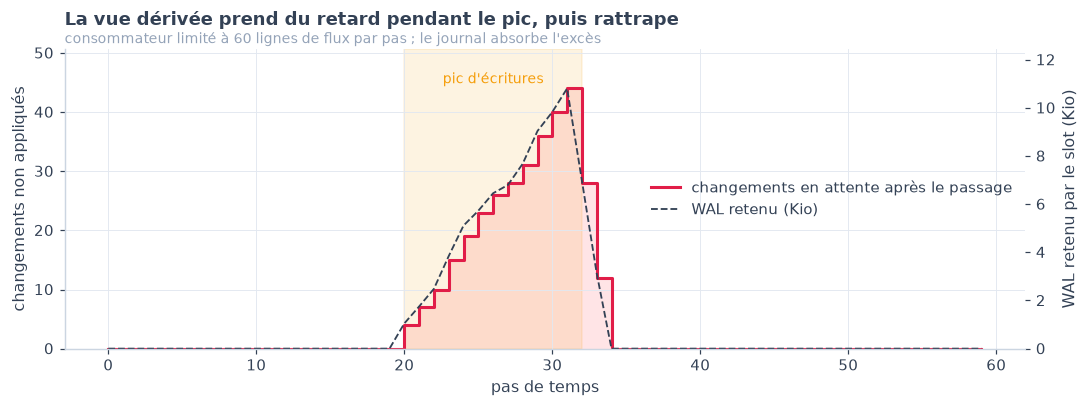

documents dans PostgreSQL : 301 | retard final : 0


In [6]:
MOTS = ["journal", "flux", "données", "index", "réplique", "cache", "requête", "événement",
        "horloge", "consensus", "transaction", "schéma", "vue", "débit", "latence", "panne",
        "courtier", "capture", "clé", "dérivée", "unicité", "audit", "idempotence", "lot"]
AUTEURS = ["ana", "bob", "chloé", "driss", "elsa", "farid"]
POIDS = [1 / (k + 1) for k in range(len(AUTEURS))]
gen = random.Random(13)
prochain_id = [100]


def phrase(n):
    return " ".join(gen.choice(MOTS) for _ in range(n)).capitalize()


def ecrire(n_tx, conn):
    """n_tx transactions : surtout des insertions, quelques mises à jour et suppressions."""
    n = 0
    for _ in range(n_tx):
        u = gen.random()
        if u < 0.7 or prochain_id[0] < 120:
            prochain_id[0] += 1
            conn.execute("INSERT INTO doc VALUES (%s, %s, %s, %s)",
                         (prochain_id[0], phrase(3), phrase(8), gen.choices(AUTEURS, POIDS)[0]))
        elif u < 0.9:
            conn.execute("UPDATE doc SET corps = %s, auteur = %s WHERE id = %s",
                         (phrase(8), gen.choices(AUTEURS, POIDS)[0], gen.randint(101, prochain_id[0])))
        else:
            conn.execute("DELETE FROM doc WHERE id = %s", (gen.randint(101, prochain_id[0]),))
        n += 1
    return n


def en_attente(slot):
    """Nombre de changements de lignes encore dans le slot (non confirmés)."""
    return sql("""SELECT count(*) FROM pg_logical_slot_peek_changes(%s, NULL, NULL)
                  WHERE data LIKE 'table %%'""", (slot,))[0][0]


def wal_retenu(slot):
    return sql("""SELECT pg_wal_lsn_diff(pg_current_wal_lsn(), confirmed_flush_lsn)
                  FROM pg_replication_slots WHERE slot_name = %s""", (slot,))[0][0]


mesures_retard = []
with psycopg.connect(DSN, autocommit=True) as w:
    for pas in range(60):
        ecrire(25 if 20 <= pas < 32 else 4, w)
        consume("vues", max_rows=60)
        mesures_retard.append((pas, en_attente("vues"), float(wal_retenu("vues"))))
ret = pd.DataFrame(mesures_retard, columns=["pas", "en attente", "WAL retenu (o)"])

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(ret["pas"], ret["en attente"], color=LIGHT[ROSE], step="post")
ax.step(ret["pas"], ret["en attente"], where="post", color=ROSE, label="changements en attente après le passage")
ax.axvspan(20, 32, color=AMBER, alpha=0.12)
ax.text(26, ret["en attente"].max() * 1.02, "pic d'écritures", ha="center", color=AMBER, fontsize=9)
ax2 = ax.twinx()
ax2.plot(ret["pas"], ret["WAL retenu (o)"] / 1024, color=SLATE, lw=1.2, ls="--", label="WAL retenu (Kio)")
ax2.set_ylabel("WAL retenu par le slot (Kio)"); ax2.grid(False)
ax.set_xlabel("pas de temps"); ax.set_ylabel("changements non appliqués")
ax.set_ylim(0, ret["en attente"].max() * 1.15)
ax.set_title("La vue dérivée prend du retard pendant le pic, puis rattrape")
subtitle(ax, "consommateur limité à 60 lignes de flux par pas ; le journal absorbe l'excès")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax2.set_ylim(0, ret["WAL retenu (o)"].max() / 1024 * 1.15)
ax.legend(h1 + h2, l1 + l2, loc="center right")
plt.tight_layout(); plt.show()
print("documents dans PostgreSQL :", sql("SELECT count(*) FROM doc")[0][0],
      "| retard final :", ret["en attente"].iloc[-1])

Pendant le pic, l'application écrit plus vite que le consommateur ne lit : l'écart
grossit, et PostgreSQL retient le WAL correspondant. Les écritures ne sont **jamais
ralenties** par la vue lente : le journal sert de tampon, et la faute (ici, une simple
lenteur) reste confinée à la vue. Une fois le pic passé, la marge de capacité résorbe le
retard. Le prix est la **fraîcheur** : pendant quelques pas, une recherche dans Redis ne
trouve pas les articles qui viennent d'être publiés, alors que PostgreSQL les contient
déjà. Vérifions la fraîcheur à un instant donné :

In [7]:
with psycopg.connect(DSN, autocommit=True) as w:
    prochain_id[0] += 1
    nid = prochain_id[0]
    w.execute("INSERT INTO doc VALUES (%s, 'Watermark tardif', 'un article tout frais', 'ana')", (nid,))
print("dans PostgreSQL :", sql("SELECT count(*) FROM doc WHERE id = %s", (nid,))[0][0] == 1,
      "| trouvé dans l'index Redis :", nid in {int(x) for x in R.smembers("idx:v1:t:watermark")})
consume("vues")
print("après passage du consommateur :", nid in {int(x) for x in R.smembers("idx:v1:t:watermark")})

dans PostgreSQL : True | trouvé dans l'index Redis : False
après passage du consommateur : True


> **À retenir.** Un consommateur de journal entretient une vue dérivée comme une base
> entretient un index, mais de façon asynchrone : une vue lente prend du retard sans
> ralentir les écritures, et le journal retenu par le slot mesure ce retard.

## 3. Panne du consommateur : relivraison et idempotence (section *Making unbundling work*)

Le consommateur avance le slot **après** avoir appliqué les changements : c'est une
livraison « au moins une fois ». S'il tombe en panne entre les deux, les changements
déjà appliqués à Redis seront **relivrés** au redémarrage. Provoquons la panne au milieu
d'un lot de 80 transactions, après 50 changements appliqués.

In [8]:
total_avant = int(R.get("idx:v1:naif_total"))
with psycopg.connect(DSN, autocommit=True) as w:
    ecrire(80, w)
lignes_lot = [d for _, _, d in peek("vues") if parse_change(d)]
try:
    consume("vues", crash_after=50)
except Crash as e:
    print("consommateur :", e)
relivres = [d for _, _, d in peek("vues") if parse_change(d)]
print(f"changements en attente avant la panne : {len(lignes_lot)} ; après la panne : {len(relivres)}"
      f" (les 50 déjà appliqués sont relivrés)")
print("au redémarrage :", consume("vues"), "changements appliqués")

consommateur : panne après 50 changements
changements en attente avant la panne : 78 ; après la panne : 78 (les 50 déjà appliqués sont relivrés)
au redémarrage : 78 changements appliqués


Comparons maintenant les vues Redis à la **vérité** recalculée depuis PostgreSQL : la
vue idempotente (compteurs par auteur) et le compteur naïf du nombre de documents.

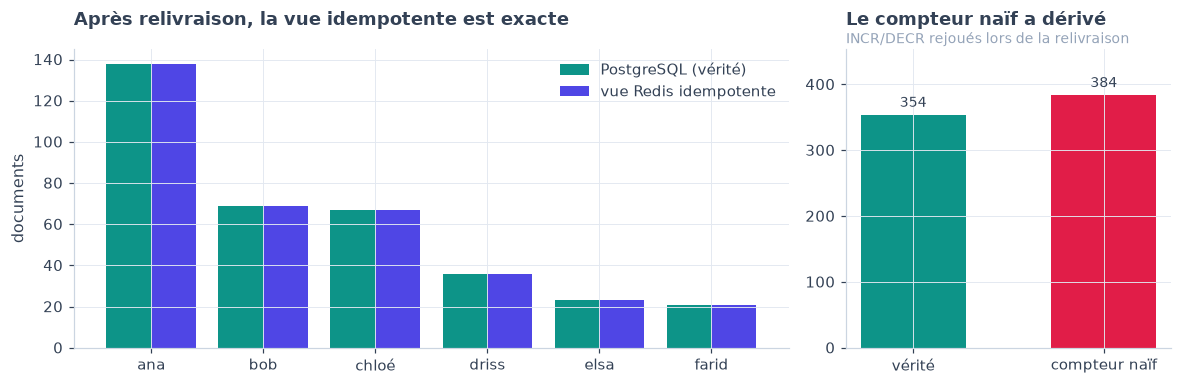

écart du compteur naïf : 30


In [9]:
verite = Counter(a for (a,) in sql("SELECT auteur FROM doc") if a)
idem = {k: int(v) for k, v in R.hgetall("idx:v1:auteurs").items() if int(v)}
comp = pd.DataFrame({"PostgreSQL (vérité)": pd.Series(verite), "vue idempotente": pd.Series(idem)}).fillna(0).astype(int)
n_vrai, n_naif = sql("SELECT count(*) FROM doc")[0][0], int(R.get("idx:v1:naif_total"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
x = np.arange(len(comp))
a1.bar(x - 0.2, comp.iloc[:, 0], 0.4, color=TEAL, label="PostgreSQL (vérité)")
a1.bar(x + 0.2, comp.iloc[:, 1], 0.4, color=INDIGO, label="vue Redis idempotente")
a1.set_xticks(x, comp.index); a1.set_ylabel("documents"); a1.legend()
a1.set_title("Après relivraison, la vue idempotente est exacte")
a2.bar(["vérité", "compteur naïf"], [n_vrai, n_naif], color=[TEAL, ROSE], width=0.55)
annotate_bars(a2, "{:.0f}")
a2.set_ylim(0, max(n_vrai, n_naif) * 1.18)
a2.set_title("Le compteur naïf a dérivé")
subtitle(a2, "INCR/DECR rejoués lors de la relivraison")
plt.tight_layout(); plt.show()
print("écart du compteur naïf :", n_naif - n_vrai)

Les compteurs par auteur coïncident exactement avec PostgreSQL : rejouer un changement
retire puis remet la même contribution. Le compteur naïf, lui, a compté deux fois les
insertions et suppressions relivrées, et son écart est **permanent** : attendre ne le
corrigera pas, c'est une violation d'**intégrité** et non de fraîcheur. Le slot garantit
l'absence de perte ; l'absence de doublon est l'affaire du consommateur.

**Le journal retenu pendant une panne longue.** Si le consommateur reste arrêté, le slot
empêche PostgreSQL de recycler le WAL : c'est ce qui permet le rattrapage sans perte,
mais un slot abandonné finit par remplir le disque (d'où le paramètre
`max_slot_wal_keep_size`). Mesurons-le pendant 40 lots d'écritures sans consommateur,
puis pendant le rattrapage.

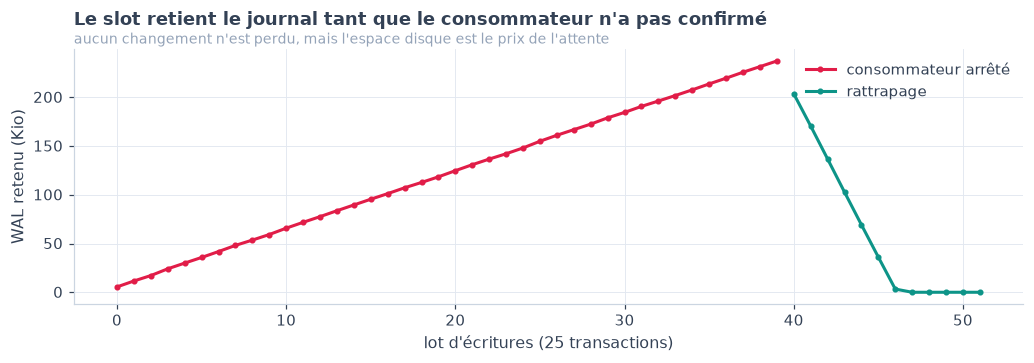

In [10]:
pts = []
with psycopg.connect(DSN, autocommit=True) as w:
    for k in range(40):
        ecrire(25, w)
        pts.append((k, float(wal_retenu("vues")), "consommateur arrêté"))
for k in range(40, 52):
    consume("vues", max_rows=400)
    pts.append((k, float(wal_retenu("vues")), "rattrapage"))
pw = pd.DataFrame(pts, columns=["lot", "wal", "phase"])
fig, ax = plt.subplots(figsize=(9.5, 3.4))
for ph, c in [("consommateur arrêté", ROSE), ("rattrapage", TEAL)]:
    s = pw[pw.phase == ph]
    ax.plot(s["lot"], s["wal"] / 1024, color=c, marker="o", ms=3, label=ph)
ax.set_xlabel("lot d'écritures (25 transactions)"); ax.set_ylabel("WAL retenu (Kio)")
ax.set_title("Le slot retient le journal tant que le consommateur n'a pas confirmé")
subtitle(ax, "aucun changement n'est perdu, mais l'espace disque est le prix de l'attente")
ax.legend(); plt.tight_layout(); plt.show()

> **À retenir.** Avancer l'offset après l'application donne « au moins une fois » :
> les pannes se traduisent par des relivraisons, inoffensives si la dérivation est
> idempotente, désastreuses (et définitives) sinon.

## 4. `CREATE INDEX CONCURRENTLY` : une vue dérivée construite par instantané et rattrapage (section *Creating an index*)

Le livre observe que créer un index sans bloquer les écritures revient à **dériver une
nouvelle vue** : parcourir un instantané cohérent de la table, puis rattraper les
écritures survenues depuis, puis suivre les écritures suivantes. C'est le même schéma
que l'ajout d'un suiveur ou l'amorçage d'une capture de changements.
`CREATE INDEX CONCURRENTLY` de PostgreSQL fait exactement cela, en plusieurs phases
visibles dans `pg_stat_progress_create_index`. Construisons un index sur une table de
1,5 million de mesures **pendant qu'un autre fil continue d'écrire**, et échantillonnons
les phases toutes les 5 ms.

In [11]:
sql("""CREATE TABLE mesures AS
       SELECT g AS id, mod(g::bigint * 7919, 50000)::integer AS capteur, random() AS valeur
       FROM generate_series(1, 1500000) g""")
sql("ALTER TABLE mesures ADD PRIMARY KEY (id)")
sql("VACUUM ANALYZE mesures")


def plan(q):
    p = sql("EXPLAIN (ANALYZE, FORMAT JSON) " + q)[0][0][0]
    return p["Plan"]["Node Type"], p["Execution Time"]


Q = "SELECT count(*) FROM mesures WHERE capteur = 4242"
avant = plan(Q)

stop, ecrits_pendant, phases = threading.Event(), [0], []


def ecrivain():
    with psycopg.connect(DSN) as c:
        nid = 2_000_000
        while not stop.is_set():
            for _ in range(50):
                nid += 1
                c.execute("INSERT INTO mesures VALUES (%s, -1, 0)", (nid,))
            time.sleep(0.02)          # transaction ouverte quelques dizaines de ms
            c.commit()
            ecrits_pendant[0] += 50


def echantillonneur(t0):
    with psycopg.connect(DSN, autocommit=True) as c:
        while not stop.is_set():
            r = c.execute("SELECT phase FROM pg_stat_progress_create_index").fetchone()
            if r:
                phases.append((time.perf_counter() - t0, r[0]))
            time.sleep(0.005)


t0 = time.perf_counter()
fils = [threading.Thread(target=ecrivain), threading.Thread(target=echantillonneur, args=(t0,))]
for f in fils:
    f.start()
time.sleep(0.2)
debut = time.perf_counter() - t0
sql("CREATE INDEX CONCURRENTLY mesures_capteur ON mesures (capteur)")
fin = time.perf_counter() - t0
time.sleep(0.1)
stop.set()
for f in fils:
    f.join()
apres = plan(Q)
with psycopg.connect(DSN, autocommit=True) as c:
    c.execute("SET enable_seqscan = off")
    via_index = c.execute("SELECT count(*) FROM mesures WHERE capteur = -1").fetchone()[0]
    c.execute("SET enable_seqscan = on; SET enable_indexscan = off; SET enable_bitmapscan = off")
    via_table = c.execute("SELECT count(*) FROM mesures WHERE capteur = -1").fetchone()[0]
print(f"construction : {fin - debut:.2f} s, pendant lesquelles {ecrits_pendant[0]} lignes ont été insérées")
print(f"lignes de l'écrivain vues par l'index : {via_index} ; par un parcours de table : {via_table}")
pd.DataFrame([("avant l'index", *avant), ("après l'index", *apres)], columns=["", "plan", "temps (ms)"])

construction : 0.39 s, pendant lesquelles 1550 lignes ont été insérées
lignes de l'écrivain vues par l'index : 1550 ; par un parcours de table : 1550


,,plan,temps (ms)
0,avant l'index,Aggregate,15.848
1,après l'index,Aggregate,0.052


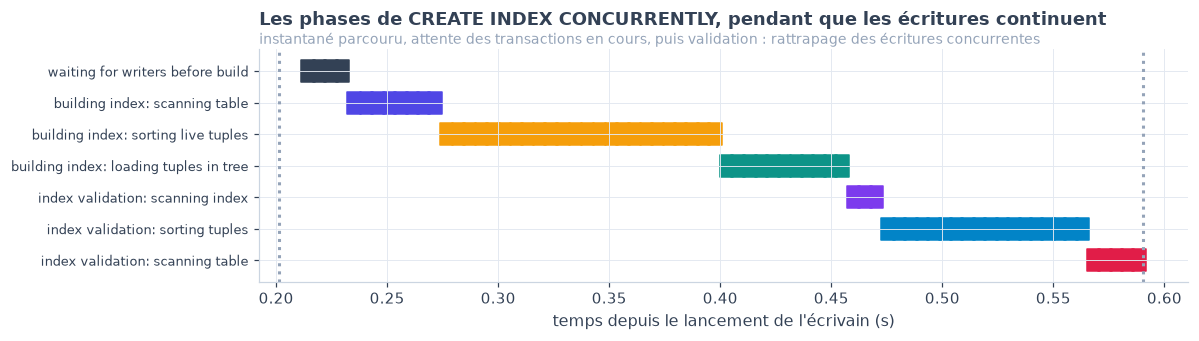

In [12]:
ph = pd.DataFrame(phases, columns=["t", "phase"])
ordre = list(dict.fromkeys(ph["phase"]))
pal_ph = [SLATE, INDIGO, AMBER, TEAL, VIOLET, SKY, ROSE, GREEN, GRAY]
couleurs = {p_: pal_ph[i % len(pal_ph)] for i, p_ in enumerate(ordre)}
fig, ax = plt.subplots(figsize=(11, 3.2))
for i, p_ in enumerate(ordre):
    t = ph.loc[ph["phase"] == p_, "t"].values
    ax.broken_barh([(x, 0.006) for x in t], (len(ordre) - 1 - i - 0.35, 0.7), color=couleurs[p_])
ax.set_yticks(range(len(ordre)), ordre[::-1], fontsize=8.5)
ax.axvline(debut, color=GRAY, ls=":"); ax.axvline(fin, color=GRAY, ls=":")
ax.set_xlabel("temps depuis le lancement de l'écrivain (s)")
ax.set_title("Les phases de CREATE INDEX CONCURRENTLY, pendant que les écritures continuent")
subtitle(ax, "instantané parcouru, attente des transactions en cours, puis validation : rattrapage des écritures concurrentes")
plt.tight_layout(); plt.show()

Les phases observées racontent la dérivation (les plus brèves peuvent échapper à
l'échantillonnage) : PostgreSQL attend que les transactions d'écriture en cours se
terminent, **construit l'index à partir d'un instantané** (parcours de la table, tri,
chargement dans l'arbre), puis entre en **validation** : il parcourt l'index et la
table pour y ajouter les lignes insérées pendant la construction (le rattrapage), et
attend enfin les transactions encore ouvertes avant de rendre l'index utilisable. Pendant tout ce temps l'écrivain n'a pas été bloqué, et toutes ses lignes
sont bien présentes dans l'index (même nombre que par un parcours de table). Le plan de
requête passe d'un parcours séquentiel à un parcours d'index, avec un gain de deux à
trois ordres de grandeur.

> **À retenir.** Un index est une vue dérivée que la base sait construire seule :
> instantané cohérent, rattrapage des écritures concurrentes, puis maintenance continue.
> Dégrouper la base, c'est appliquer le même procédé à des systèmes différents.

## 5. Faire confiance, mais vérifier : audit de bout en bout d'une vue dérivée (section *Trust, but Verify*)

Une vue dérivée n'est correcte que si toute la chaîne l'est : le décodage, le parseur,
le consommateur, le réseau, Redis... et la fonction de dérivation elle-même. Le livre
recommande de **vérifier de bout en bout** : recalculer la vue depuis la source et la
comparer à la vue entretenue. Ici, on recalcule l'index en Python depuis un `SELECT`
sur PostgreSQL (fonction `rebuild_index`) et on compare, document par document, les
termes indexés dans Redis.

In [13]:
def vue_redis(v):
    p = f"idx:{v}:doc:"
    return {int(k[len(p):]): R.smembers(k) for k in R.scan_iter(p + "*", count=1000)}


def lignes_doc():
    return [dict(zip(["id", "titre", "corps", "auteur"], r))
            for r in sql("SELECT id, titre, corps, auteur FROM doc ORDER BY id")]


def audit(v):
    """Compare la vue Redis `v` au recalcul complet depuis PostgreSQL, document par document."""
    attendus = {i: t for i, t in rebuild_index(lignes_doc()).doc_terms.items() if t}
    obs = vue_redis(v)
    faux = sorted(i for i in set(attendus) | set(obs) if attendus.get(i, set()) != obs.get(i, set()))
    return {"documents": len(attendus), "divergents": len(faux), "exemples": faux[:5]}


consume("vues")
print("audit de la vue v1 :", audit("v1"))

audit de la vue v1 : {'documents': 949, 'divergents': 0, 'exemples': []}


L'audit est propre : malgré la panne et les relivraisons de la section 3, la vue est
exactement celle qu'on obtient en recalculant tout. Introduisons maintenant un **bogue**
réaliste : une nouvelle version du consommateur est déployée avec une analyse de texte
qui **oublie de retirer les accents**. Elle traite 150 nouvelles transactions.

In [14]:
def tokenize_bogue(text):
    """Version « refactorisée » : minuscules et mots vides, mais plus de retrait des accents."""
    import re
    mots = re.findall(r"\w+", (text or "").lower())
    return {m[:-1] if len(m) > 3 and m.endswith("s") else m
            for m in mots if len(m) >= 2 and m not in {"le", "la", "les", "de", "des", "du", "un", "une", "et"}}


with psycopg.connect(DSN, autocommit=True) as w:
    ecrire(150, w)
consume("vues", tok=tokenize_bogue)
a_bogue = audit("v1")
print("audit après le déploiement bogué :", a_bogue)
rech = lambda v, mot: len(R.smembers(f"idx:{v}:t:{mot}"))
attendu_donnees = len([1 for (t, c) in sql("SELECT titre, corps FROM doc")
                       if "donnee" in tokenize(t) | tokenize(c)])
print(f"documents contenant « données » : {attendu_donnees} ; trouvés par la recherche « donnee » : "
      f"{rech('v1', 'donnee')}")

audit après le déploiement bogué : {'documents': 1037, 'divergents': 129, 'exemples': [237, 273, 292, 334, 383]}
documents contenant « données » : 391 ; trouvés par la recherche « donnee » : 336


Le bogue ne provoque **aucune erreur** : le consommateur tourne, Redis répond, les
requêtes renvoient des résultats plausibles. Seule la comparaison de bout en bout le
révèle : une partie des documents traités par la nouvelle version est indexée sous
`données` au lieu de `donnee`, et la recherche normale ne les trouve plus. Sans audit,
la corruption serait découverte (peut-être) par un utilisateur, bien plus tard.

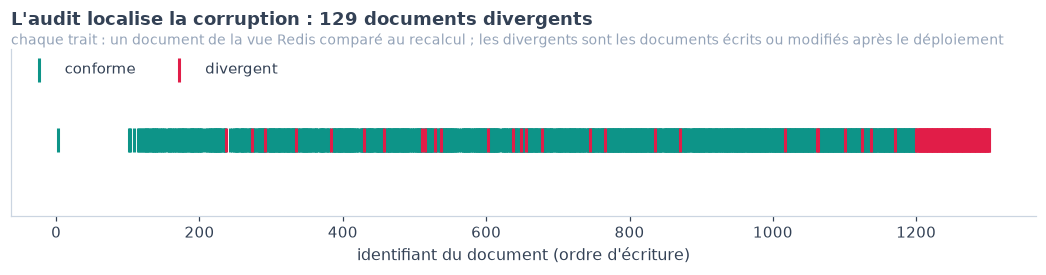

In [15]:
obs = vue_redis("v1")
ids = sorted(obs)
ref = rebuild_index(lignes_doc())
ok = np.array([obs[i] == ref.doc_terms.get(i, set()) for i in ids])
fig, ax = plt.subplots(figsize=(10.5, 2.6))
ax.scatter(np.array(ids)[ok], np.zeros(ok.sum()), marker="|", s=250, color=TEAL, label="conforme")
ax.scatter(np.array(ids)[~ok], np.zeros((~ok).sum()), marker="|", s=250, color=ROSE, label="divergent")
ax.set_yticks([]); ax.set_xlabel("identifiant du document (ordre d'écriture)")
ax.set_title(f"L'audit localise la corruption : {(~ok).sum()} documents divergents")
subtitle(ax, "chaque trait : un document de la vue Redis comparé au recalcul ; les divergents sont les documents écrits ou modifiés après le déploiement")
ax.set_ylim(-1, 1.2); ax.legend(loc="upper left", ncol=2); ax.grid(False)
plt.tight_layout(); plt.show()

Les divergences touchent tous les documents créés depuis le déploiement (la bande rouge
à droite) et, plus loin dans le passé, les anciens documents modifiés depuis (traits
rouges isolés) : l'audit date le bogue et délimite les dégâts. Parce que le flux de données est **explicite et
déterministe**, on sait aussi comment réparer : il suffit de recalculer.

> **À retenir.** Un bogue de dérivation ne fait pas planter le système, il le corrompt
> en silence. Recalculer périodiquement la vue depuis la source et comparer est le seul
> contrôle qui couvre toute la chaîne.

## 6. Corriger par retraitement : dériver une nouvelle vue à côté de l'ancienne (section *Reprocessing data for application evolution*)

Pour réparer (ou pour faire évoluer la structure d'une vue), on ne modifie pas la vue
en place : on **dérive une nouvelle vue** `v2` avec le code corrigé, à côté de `v1` qui
continue de servir les lectures, puis on bascule. Comme pour `CREATE INDEX
CONCURRENTLY`, la nouvelle vue se construit par instantané et rattrapage :

1. créer **d'abord** un nouveau slot `vues_v2` (toutes les écritures validées après ce
   point y seront) ;
2. lire un instantané de la table et l'indexer dans `v2` ;
3. consommer `vues_v2` pour rattraper.

Les écritures validées entre la création du slot et l'instantané sont vues deux fois
(dans l'instantané et dans le slot) : ce n'est pas grave, car chaque changement porte
l'image complète de la ligne, et l'application est idempotente. Les écritures
continuent pendant toute l'opération (un fil écrit 200 transactions en parallèle).

In [16]:
sql("SELECT pg_create_logical_replication_slot('vues_v2', 'test_decoding')")
fil = threading.Thread(target=lambda: ecrire(200, psycopg.connect(DSN, autocommit=True)))
fil.start()
t0 = time.perf_counter()
for r in sql("SELECT id, titre, corps, auteur FROM doc"):
    apply_redis({"op": "INSERT", "row": dict(zip(["id", "titre", "corps", "auteur"], r)), "old": None}, "v2")
t_snap = time.perf_counter() - t0
fil.join()
n1, n2 = consume("vues", tok=tokenize_bogue), consume("vues_v2", v="v2")   # v1 suit toujours (avec le bogue)
print(f"instantané indexé en {t_snap:.2f} s ; rattrapage : v1 {n1}, v2 {n2} changements")
au = pd.DataFrame([audit("v1"), audit("v2")], index=["v1 (code bogué)", "v2 (retraitée)"])
au

instantané indexé en 0.18 s ; rattrapage : v1 190, v2 190 changements


,documents,divergents,exemples
v1 (code bogué),1157,294,"[142, 219, 230, 237, 272]"
v2 (retraitée),1157,0,[]


La vue `v2` est conforme, `v1` reste corrompue. On peut alors **basculer
progressivement** les lectures : une fraction des requêtes vers `v2`, en vérifiant que
tout va bien, puis toutes. À chaque étape, revenir en arrière est trivial, puisque `v1`
existe toujours : c'est le principe des rails à double écartement que le livre utilise
comme analogie (encadré *Schema Migrations on Railways*). Simulons la bascule avec la
recherche « donnee » : la proportion de documents retrouvés suit la fraction des
lectures servies par `v2`.

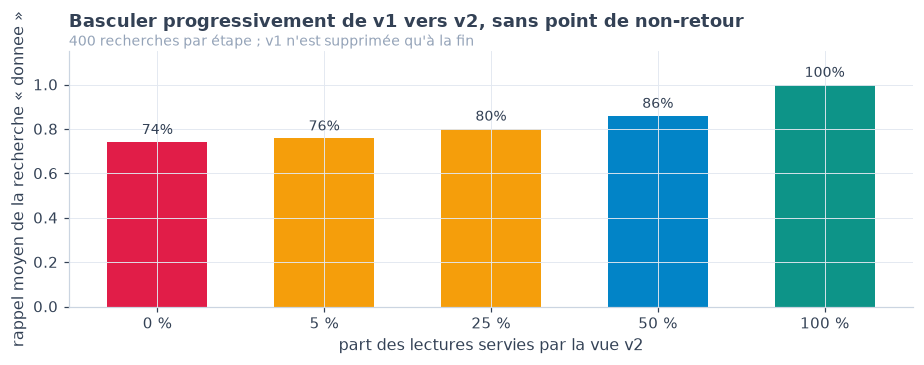

slots restants : [('vues_v2',)]


In [17]:
alias_rng = random.Random(4)
vrais = {int(x) for x in R.smembers("idx:v2:t:donnee")}   # v2 est conforme (audit ci-dessus)
etapes = [0, 0.05, 0.25, 0.5, 1.0]
rappel = []
for f in etapes:
    trouves = []
    for _ in range(400):
        v = "v2" if alias_rng.random() < f else "v1"
        trouves.append(len({int(x) for x in R.smembers(f"idx:{v}:t:donnee")} & vrais) / len(vrais))
    rappel.append(np.mean(trouves))
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.bar([f"{int(f * 100)} %" for f in etapes], rappel, color=[ROSE, AMBER, AMBER, SKY, TEAL], width=0.6)
annotate_bars(ax, "{:.0%}")
ax.set_ylim(0, 1.15); ax.set_ylabel("rappel moyen de la recherche « donnee »")
ax.set_xlabel("part des lectures servies par la vue v2")
ax.set_title("Basculer progressivement de v1 vers v2, sans point de non-retour")
subtitle(ax, "400 recherches par étape ; v1 n'est supprimée qu'à la fin")
plt.tight_layout(); plt.show()

# basculement terminé : on supprime l'ancienne vue et son slot
for k in R.scan_iter("idx:v1:*", count=1000):
    R.delete(k)
sql("SELECT pg_drop_replication_slot('vues')")
print("slots restants :", sql("SELECT slot_name FROM pg_replication_slots"))

> **À retenir.** Une vue dérivée se corrige en la redérivant : nouveau slot, instantané,
> rattrapage, puis bascule progressive et réversible. Supprimer l'ancienne vue est la
> dernière étape, pas la première.

## 7. Identifiants de requête de bout en bout (sections *The End-to-End Argument for Databases* et *Uniquely identifying requests*)

Passons du côté des écritures. Un client demande un virement ; le serveur exécute la
transaction et la valide, mais la réponse se perd (réseau mobile, délai expiré). Le
client ne sait pas si le virement a eu lieu et **réessaie**. Pour la base, c'est une
nouvelle transaction : la protection de TCP contre les doublons ne vaut qu'à
l'intérieur d'une connexion, et les transactions ne voient pas au-delà de la leur.

Expérience : 8 clients concurrents effectuent chacun 40 virements entre 20 comptes. Pour
chaque tentative, le « réseau » perd la connexion **avant** la validation avec
probabilité 0,1 (la transaction est annulée) et perd la **réponse** après validation
avec probabilité 0,2. Le client réessaie jusqu'à obtenir une réponse. Le serveur
fonctionne en deux modes : naïf, ou avec un identifiant de requête généré **par le
client** et une contrainte `UNIQUE` sur la table `requetes`.

In [18]:
class ConnexionPerdue(Exception):
    pass


def preparer_banque():
    sql("DROP TABLE IF EXISTS comptes, requetes, journal_effets")
    sql("CREATE TABLE comptes (id integer PRIMARY KEY, solde numeric NOT NULL)")
    sql("INSERT INTO comptes SELECT g, 1000 FROM generate_series(1, 20) g")
    sql("""CREATE TABLE requetes (request_id uuid UNIQUE, src integer, dst integer, montant numeric)""")
    sql("CREATE TABLE journal_effets (request_id uuid)")   # instrumentation : une ligne par exécution


def serveur_virement(conn, req_id, src, dst, montant, dedup, alea):
    """Exécute un virement. Renvoie 'ok' ou 'déjà fait' ; lève ConnexionPerdue si le client
    ne reçoit pas de réponse (avant ou après la validation)."""
    try:
        with conn.transaction():
            if dedup:
                conn.execute("INSERT INTO requetes VALUES (%s, %s, %s, %s)", (req_id, src, dst, montant))
            conn.execute("UPDATE comptes SET solde = solde + %s WHERE id = %s", (montant, dst))
            conn.execute("UPDATE comptes SET solde = solde - %s WHERE id = %s", (montant, src))
            conn.execute("INSERT INTO journal_effets VALUES (%s)", (req_id,))
            if alea.random() < 0.1:
                raise ConnexionPerdue("avant validation")      # rollback
    except errors.UniqueViolation:
        return "déjà fait"
    if alea.random() < 0.2:
        raise ConnexionPerdue("réponse perdue")                # validé, mais le client l'ignore
    return "ok"


def client(k, dedup):
    alea = random.Random(1000 + k)
    attendu, tentatives = Counter(), 0
    with psycopg.connect(DSN, autocommit=True) as conn:
        for _ in range(40):
            src, dst = alea.sample(range(1, 21), 2)
            montant = alea.randint(1, 50)
            req_id = uuid.UUID(int=alea.getrandbits(128))     # généré une fois, réutilisé à chaque relance
            attendu[src] -= montant; attendu[dst] += montant
            while True:
                tentatives += 1
                try:
                    serveur_virement(conn, req_id, src, dst, montant, dedup, alea)
                    break
                except ConnexionPerdue:
                    continue
                except errors.DeadlockDetected:
                    continue
    return attendu, tentatives


resultats = {}
for mode, dedup in [("naïf", False), ("identifiant de requête", True)]:
    preparer_banque()
    with ThreadPoolExecutor(8) as ex:
        sorties = list(ex.map(lambda k: client(k, dedup), range(8)))
    attendu = Counter()
    for s in sorties:
        attendu.update(s[0])          # update garde les valeurs négatives
    soldes = dict(sql("SELECT id, solde FROM comptes"))
    ecart = sum(abs(float(soldes[i]) - (1000 + attendu[i])) for i in range(1, 21))
    execs = Counter(n for (_, n) in sql("SELECT request_id, count(*) FROM journal_effets GROUP BY 1"))
    resultats[mode] = dict(tentatives=sum(s[1] for s in sorties), executions=execs,
                           ecart=ecart, total=float(sum(soldes.values())))
pd.DataFrame({m: {"tentatives": r["tentatives"], "virements exécutés 2 fois ou plus":
                  sum(v for n, v in r["executions"].items() if n >= 2),
                  "somme des soldes": r["total"], "écart total aux soldes attendus": r["ecart"]}
              for m, r in resultats.items()})

,naïf,identifiant de requête
tentatives,462.0,418.0
virements exécutés 2 fois ou plus,62.0,0.0
somme des soldes,20000.0,20000.0
écart total aux soldes attendus,2460.0,0.0


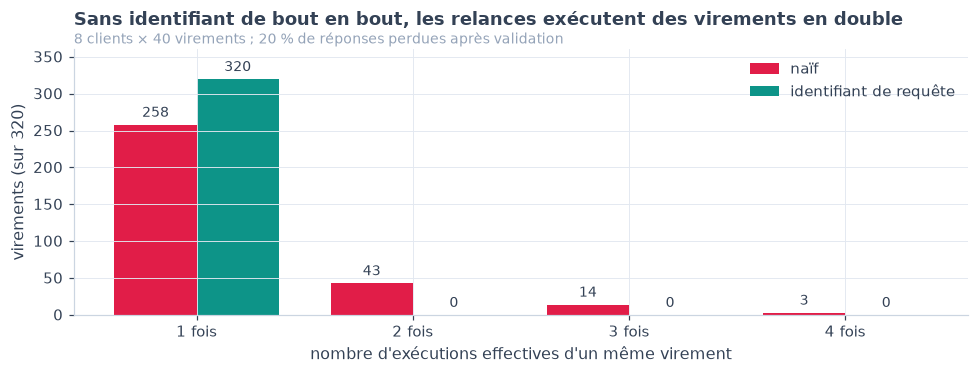

In [19]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ks = [1, 2, 3, 4]
for j, (m, c) in enumerate([("naïf", ROSE), ("identifiant de requête", TEAL)]):
    ax.bar(np.array(ks) + (j - 0.5) * 0.38, [resultats[m]["executions"].get(k, 0) for k in ks], 0.38,
           color=c, label=m)
annotate_bars(ax, "{:.0f}")
ax.set_xticks(ks, ["1 fois", "2 fois", "3 fois", "4 fois"]); ax.set_ylim(0, 360)
ax.set_xlabel("nombre d'exécutions effectives d'un même virement"); ax.set_ylabel("virements (sur 320)")
ax.set_title("Sans identifiant de bout en bout, les relances exécutent des virements en double")
subtitle(ax, "8 clients × 40 virements ; 20 % de réponses perdues après validation")
ax.legend(); plt.tight_layout(); plt.show()

Remarquez que la **somme des soldes** reste égale à 20 000 dans les deux modes : chaque
transaction est atomique, donc aucun argent n'est créé ni détruit. Et pourtant, en mode
naïf, des dizaines de virements ont été exécutés deux fois ou plus, et les soldes
s'écartent des soldes voulus. L'atomicité des transactions est une garantie **locale** ;
l'exécution « exactement une fois » d'une intention de l'utilisateur est une propriété
**de bout en bout**, qui exige que l'identifiant naisse chez le client et voyage jusqu'à
la base. Avec l'identifiant, chaque virement est exécuté exactement une fois, malgré un
nombre de tentatives comparable.

**Le double clic.** Que se passe-t-il si deux soumissions du même identifiant arrivent
**en même temps** ? La première insère l'identifiant sans encore valider ; la seconde
tente la même insertion et **attend** le verrou de l'entrée d'index unique ; quand la
première valide, la seconde échoue avec une violation d'unicité.

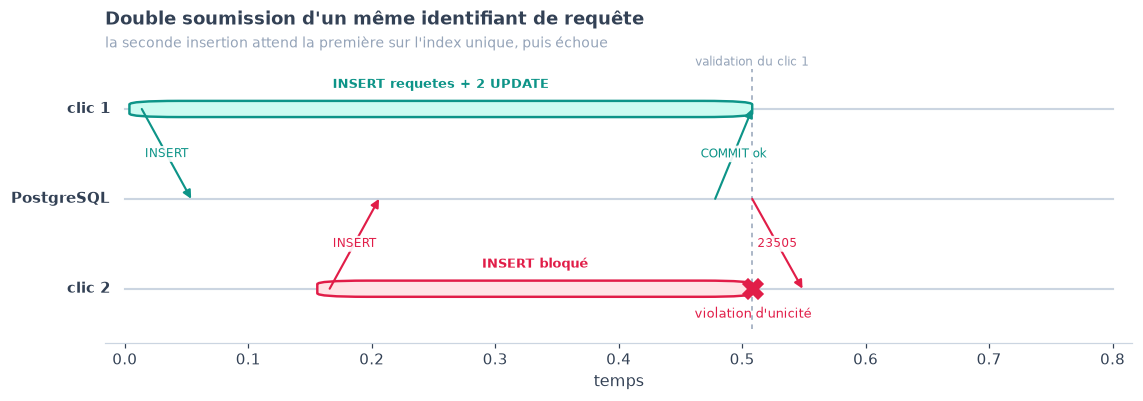

{'clic 1 début': 0.0, 'clic 2 début': 0.16, 'clic 1 fin': 0.51, 'clic 1 issue': 'validé', 'clic 2 fin': 0.51, 'clic 2 issue': "violation d'unicité"}
soldes : [(1, Decimal('989')), (2, Decimal('1011'))]


In [20]:
preparer_banque()
rid = uuid.UUID(int=42)
trace, t0 = {}, time.perf_counter()


def soumission(nom, attente, duree):
    time.sleep(attente)
    with psycopg.connect(DSN, autocommit=True) as conn:
        trace[nom + " début"] = time.perf_counter() - t0
        try:
            with conn.transaction():
                conn.execute("INSERT INTO requetes VALUES (%s, 1, 2, 11)", (rid,))
                conn.execute("UPDATE comptes SET solde = solde + 11 WHERE id = 2")
                conn.execute("UPDATE comptes SET solde = solde - 11 WHERE id = 1")
                time.sleep(duree)
            trace[nom + " fin"], trace[nom + " issue"] = time.perf_counter() - t0, "validé"
        except errors.UniqueViolation:
            trace[nom + " fin"], trace[nom + " issue"] = time.perf_counter() - t0, "violation d'unicité"


fs = [threading.Thread(target=soumission, args=("clic 1", 0.0, 0.5)),
      threading.Thread(target=soumission, args=("clic 2", 0.15, 0.0))]
for f in fs:
    f.start()
for f in fs:
    f.join()
st = SpaceTime(["clic 1", "PostgreSQL", "clic 2"], t_max=0.8, width=10.5,
               title="Double soumission d'un même identifiant de requête",
               subtitle="la seconde insertion attend la première sur l'index unique, puis échoue")
st.op("clic 1", trace["clic 1 début"], trace["clic 1 fin"], "INSERT requetes + 2 UPDATE", color=TEAL)
st.op("clic 2", trace["clic 2 début"], trace["clic 2 fin"], "INSERT bloqué", color=ROSE)
st.msg("clic 1", trace["clic 1 début"] + 0.01, "PostgreSQL", trace["clic 1 début"] + 0.05, "INSERT", color=TEAL)
st.msg("clic 2", trace["clic 2 début"] + 0.01, "PostgreSQL", trace["clic 2 début"] + 0.05, "INSERT", color=ROSE)
st.msg("PostgreSQL", trace["clic 1 fin"] - 0.03, "clic 1", trace["clic 1 fin"], "COMMIT ok", color=TEAL)
st.msg("PostgreSQL", trace["clic 1 fin"], "clic 2", trace["clic 2 fin"] + 0.04, "23505", color=ROSE)
st.event("clic 2", trace["clic 2 fin"], "violation d'unicité", kind="crash")
st.vline(trace["clic 1 fin"], "validation du clic 1")
st.show()
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in trace.items()})
print("soldes :", sql("SELECT id, solde FROM comptes WHERE id IN (1, 2) ORDER BY id"))

Le second clic reste bloqué environ 0,35 s, exactement jusqu'à la validation du premier,
puis échoue avec le code `23505` ; les soldes n'ont bougé qu'une fois. Une base
relationnelle maintient correctement une contrainte d'unicité **même en `READ
COMMITTED`**, alors qu'une vérification applicative « lire puis insérer » n'y
parviendrait pas (section suivante). La table `requetes` joue en outre le rôle d'un
**journal d'événements** : les mises à jour des soldes pourraient en être dérivées par
un consommateur, comme dans les sections 1 à 3.

> **À retenir.** Ni TCP, ni les transactions, ni un traitement de flux « exactement une
> fois » ne suppriment à eux seuls les doublons créés par les relances d'un utilisateur :
> il faut un identifiant de requête créé à l'extrémité et vérifié par une contrainte
> d'unicité à l'autre extrémité.

## 8. Contraintes d'unicité sous concurrence (sections *Uniqueness constraints require consensus* et *Uniqueness in log-based messaging*)

Faire respecter l'unicité, c'est décider, entre requêtes concurrentes portant la même
valeur, laquelle gagne : une forme de consensus, que l'on obtient en faisant passer
toutes les requêtes en conflit par un même point de décision. Comparons quatre façons
d'attribuer des noms d'utilisateur, avec 8 clients qui réclament le **même** nom au même
instant (une barrière les synchronise), sur 25 noms successifs :

- **lire puis insérer** en `READ COMMITTED`, sans contrainte (avec une petite pause de
  2 ms entre la vérification et l'insertion, comme une logique applicative) ;
- **lire puis insérer** en `SERIALIZABLE` (isolation par instantané sérialisable) ;
- **contrainte `UNIQUE`** : on insère directement, la base tranche ;
- **journal + traitement séquentiel** : chaque client **ajoute sa demande** à une table
  journal (ordre fixé par une séquence), puis un processeur unique parcourt le journal
  dans l'ordre et accorde le nom à la première demande ; c'est l'approche du livre pour
  une base dégroupée (un processeur par shard du journal).

In [21]:
sql("CREATE TABLE utilisateurs (nom text, client integer)")
sql("CREATE TABLE utilisateurs_u (nom text UNIQUE, client integer)")
sql("CREATE TABLE demandes_noms (seq bigserial PRIMARY KEY, nom text, client integer)")
N_CLIENTS, N_NOMS = 8, 25


def course(strategie, nom):
    barriere = threading.Barrier(N_CLIENTS)
    issues = Counter()
    verrou = threading.Lock()

    def tenter(k):
        with psycopg.connect(DSN, autocommit=True) as c:
            niveau = "SERIALIZABLE" if strategie == "lire puis insérer (SERIALIZABLE)" else "READ COMMITTED"
            barriere.wait()
            try:
                if strategie.startswith("lire puis insérer"):
                    with c.transaction():
                        c.execute(f"SET TRANSACTION ISOLATION LEVEL {niveau}")
                        n = c.execute("SELECT count(*) FROM utilisateurs WHERE nom = %s", (nom,)).fetchone()[0]
                        time.sleep(0.002)
                        if n == 0:
                            c.execute("INSERT INTO utilisateurs VALUES (%s, %s)", (nom, k))
                            res = "accordé"
                        else:
                            res = "refusé (déjà pris)"
                elif strategie == "contrainte UNIQUE":
                    c.execute("INSERT INTO utilisateurs_u VALUES (%s, %s)", (nom, k))
                    res = "accordé"
                else:
                    c.execute("INSERT INTO demandes_noms (nom, client) VALUES (%s, %s)", (nom, k))
                    res = "demande journalisée"
            except errors.UniqueViolation:
                res = "refusé (violation d'unicité)"
            except errors.SerializationFailure:
                res = "annulé (échec de sérialisation)"
        with verrou:
            issues[res] += 1

    with ThreadPoolExecutor(N_CLIENTS) as ex:
        list(ex.map(tenter, range(N_CLIENTS)))
    return issues


strategies = ["lire puis insérer (READ COMMITTED)", "lire puis insérer (SERIALIZABLE)",
              "contrainte UNIQUE", "journal + traitement séquentiel"]
prefixes = dict(zip(strategies, ["rc", "ser", "uq", "log"]))
issues = {s: Counter() for s in strategies}
for s in strategies:
    for j in range(N_NOMS):
        issues[s].update(course(s, f"{prefixes[s]}_{j}"))


def processeur_journal():
    """Processeur séquentiel du journal : premier arrivé, premier servi."""
    pris, decisions = {}, Counter()
    for seq, nom, k in sql("SELECT seq, nom, client FROM demandes_noms ORDER BY seq"):
        if nom in pris:
            decisions["refusé (déjà pris)"] += 1
        else:
            pris[nom] = k
            decisions["accordé"] += 1
    return pris, decisions


pris, decisions = processeur_journal()
del issues[strategies[3]]["demande journalisée"]
issues[strategies[3]].update(decisions)
titulaires = {s: [n for _, n in sql("SELECT nom, count(*) FROM utilisateurs WHERE nom LIKE %s GROUP BY nom",
                                    (prefixes[s] + "_%",))] for s in strategies[:2]}
titulaires[strategies[2]] = [n for _, n in sql("SELECT nom, count(*) FROM utilisateurs_u GROUP BY nom")]
titulaires[strategies[3]] = [1] * len(pris)
tab = pd.DataFrame(issues).T.reindex(strategies).fillna(0).astype(int)
tab["titulaires par nom (moy.)"] = [np.mean(titulaires[s]) for s in strategies]
tab["max"] = [max(titulaires[s]) for s in strategies]
tab

,accordé,annulé (échec de sérialisation),refusé (violation d'unicité),refusé (déjà pris),titulaires par nom (moy.),max
lire puis insérer (READ COMMITTED),200,0,0,0,8.0,8
lire puis insérer (SERIALIZABLE),25,175,0,0,1.0,1
contrainte UNIQUE,25,0,175,0,1.0,1
journal + traitement séquentiel,25,0,0,175,1.0,1


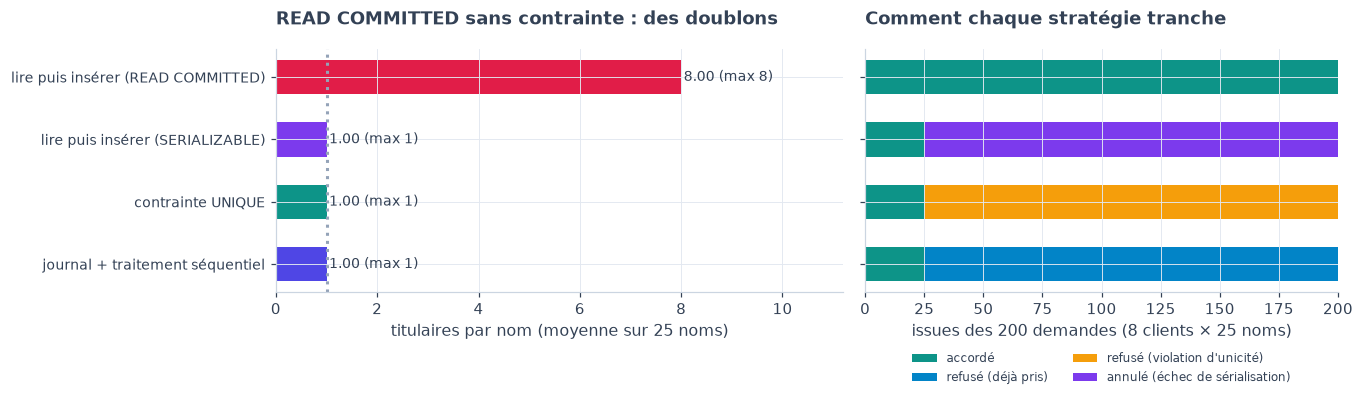

In [22]:
cols = ["accordé", "refusé (déjà pris)", "refusé (violation d'unicité)", "annulé (échec de sérialisation)"]
pal = dict(zip(cols, [TEAL, SKY, AMBER, VIOLET]))
y = np.arange(len(strategies))[::-1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 3.9), gridspec_kw={"width_ratios": [1.2, 1]})
moy = tab["titulaires par nom (moy.)"].values
a1.barh(y, moy, color=[ROSE, VIOLET, TEAL, INDIGO], height=0.55)
for yi, m, M in zip(y, moy, tab["max"].values):
    a1.text(m + 0.05, yi, f"{m:.2f} (max {M})", va="center", fontsize=9)
a1.set_yticks(y, strategies, fontsize=9); a1.axvline(1, color=GRAY, ls=":")
a1.set_xlim(0, max(moy) * 1.4); a1.set_xlabel("titulaires par nom (moyenne sur 25 noms)")
a1.set_title("READ COMMITTED sans contrainte : des doublons")
left = np.zeros(len(strategies))
for col in cols:
    vals = tab[col].values if col in tab else np.zeros(len(strategies))
    a2.barh(y, vals, left=left, color=pal[col], height=0.55, label=col)
    left += vals
a2.set_yticks(y, [""] * len(strategies)); a2.set_xlim(0, 200)
a2.set_xlabel("issues des 200 demandes (8 clients × 25 noms)")
a2.set_title("Comment chaque stratégie tranche")
a2.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout(); plt.show()

Les résultats d'une course entre fils dépendent de l'ordonnanceur et varient d'une
exécution à l'autre, mais l'ordre de grandeur est stable :

- **lire puis insérer en `READ COMMITTED`** accorde chaque nom à plusieurs clients, très
  souvent aux huit : tous lisent « 0 titulaire » pendant la pause, avant que l'un d'eux
  n'insère. C'est
  le write skew du chapitre 8, appliqué à une insertion (un fantôme) ;
- en **`SERIALIZABLE`**, PostgreSQL détecte le conflit lecture-écriture et annule les
  transactions en trop (`40001`) : un seul titulaire, au prix d'annulations à rejouer ;
- la **contrainte `UNIQUE`** tranche au moment de l'insertion : un gagnant, sept
  violations d'unicité, sans aucune logique applicative ;
- le **journal + traitement séquentiel** ne rejette rien au moment de l'écriture :
  toutes les demandes sont acceptées dans le journal, et c'est l'**ordre du journal** qui
  décide, de façon déterministe, en relisant le journal sur un seul fil. Le client
  apprend le verdict en lisant le flux de sortie. Le débit se répartit en découpant le
  journal selon le hachage du nom : les demandes en conflit tombent toujours dans la même
  shard.

Les trois dernières stratégies font toutes passer les demandes en conflit par un point
de décision unique (le verrou de l'index unique, le détecteur de conflits de SSI, ou le
fil qui lit le journal) : c'est en cela que l'unicité exige un consensus.

> **À retenir.** Une vérification applicative « lire puis insérer » ne protège pas une
> contrainte d'unicité sous concurrence. Il faut un point de décision unique par valeur :
> une contrainte de la base, la sérialisabilité, ou un journal ordonné lu séquentiellement.

## Synthèse

- Un **slot de réplication logique** fait de PostgreSQL un producteur de journal : les
  changements validés y sont rangés dans l'ordre de validation, et le slot est un offset
  durable qui retient le WAL tant que le consommateur n'a pas confirmé (section 1).
- Un consommateur qui applique ces changements à Redis entretient des **vues
  dérivées** (index inversé, compteurs) comme une base entretient ses index, mais de
  façon **asynchrone** : une vue lente prend du retard sans freiner les écritures
  (section 2).
- Avancer l'offset après l'application donne « au moins une fois » : les pannes du
  consommateur deviennent des relivraisons, inoffensives pour une dérivation
  **idempotente**, définitives pour un compteur naïf (section 3).
- `CREATE INDEX CONCURRENTLY` montre le procédé de dérivation d'une vue sous charge :
  instantané, attente, rattrapage (section 4).
- Un bogue de dérivation corrompt en silence ; seul un **audit de bout en bout** (recalcul
  depuis la source et comparaison) le révèle, et le **retraitement** (nouveau slot,
  instantané, rattrapage, bascule progressive) le répare sans interruption (sections 5
  et 6).
- Côté écritures, l'**argument de bout en bout** s'applique aux relances : seul un
  identifiant de requête né chez le client et protégé par une contrainte d'unicité
  garantit qu'une intention est exécutée exactement une fois (section 7).
- L'unicité sous concurrence exige un **point de décision unique** par valeur :
  contrainte, sérialisabilité ou journal lu séquentiellement (section 8).

Liens : capture de changements et offsets (chapitre 12), index et index
secondaires (chapitre 4), write skew et SSI (chapitre 8),
consensus et diffusion totalement ordonnée (chapitre 10).

Pensez à arrêter les services :
`docker compose -f docker/dataflow/compose.yml -p ddia_dataflow down -v`.